# Replication of H1 and H2 on a second trading day

Notebooks 02 (H1) and 03 (H2) use a single session, AAPL on **2019-12-30**. A result obtained on
one day can depend on that day: its volatility, its spread, or a few large moves. This notebook
runs the same pipeline, unchanged, on a second session, **2019-07-30**, and asks whether the
conclusions still hold.

- **H1**: adding the total order flow imbalance (OFI) to the static book features improves the
  5-second mid-price forecast (M1 vs M2).
- **H2**: splitting the OFI by message type (add, cancel, execution, replace) improves it further
  (M2 vs M3).

1. [Data](#data)
2. [Each day on its own](#within)
3. [Training on one day, testing on the other](#cross)
4. [Coefficients of the decomposed flow](#coefficients)
5. [Conclusion and limits](#conclusion)

<a id="data"></a>

## 1. Data

The second day comes from the same Nasdaq TotalView-ITCH 5.0 archive
(`07302019.NASDAQ_ITCH50.gz`, about 3.7 GB). It was converted with the repository converter
(`uv run itch-convert --source data/raw/07302019.NASDAQ_ITCH50.gz`), which runs the same
validation checks as for December 30. We chose July 30 because it is a regular session with no
scheduled announcement during market hours: Apple reported its quarterly results after the close
that day, and the Fed decision came the day after.

To keep the repository light, we do not commit the converted file of July 30 (19 MB), only the
1-second grids of both days (`data/default/AAPL_grids_1s.parquet`, about 1 MB), which hold
everything the models need.
`load_sessions` rebuilds a grid from the event file when it is present (`data/processed/` or
`data/default/`) and otherwise reads it from that file. The book replay, the OFI and the grid
are the functions of `flow_study.py`, the ones notebook 03 checks against notebook 02.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from analysis.flow_study import (
    FLOW,
    GROUPS,
    STATIC,
    clark_west,
    fit_predict,
    load_sessions,
    scores,
    split_day,
    wald_equal_coefficients,
)

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "font.size": 10,
    }
)

ROOT = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "pyproject.toml").is_file() and (candidate / "common/schema.py").is_file()
)
days = load_sessions(
    event_dirs=[ROOT / "data/processed", ROOT / "data/default"],
    cache_path=ROOT / "data/default/AAPL_grids_1s.parquet",
)
print("sessions:", ", ".join(str(day) for day in days))

summary = pd.DataFrame(
    {
        "1s rows": {d: len(g) for d, g in days.items()},
        "mid open ($)": {d: g["mid_price"].iloc[0] for d, g in days.items()},
        "mid close ($)": {d: g["mid_price"].iloc[-1] for d, g in days.items()},
        "spread (ticks)": {d: 100 * g["spread"].mean() for d, g in days.items()},
        "target sd (ticks)": {d: g["target"].std() for d, g in days.items()},
        "target = 0 (%)": {d: 100 * (g["target"] == 0).mean() for d, g in days.items()},
        "sd of 1s OFI": {d: g["ofi"].std() for d, g in days.items()},
    }
)
print(summary.round(2).to_string())

sessions: 2019-07-30, 2019-12-30
            1s rows  mid open ($)  mid close ($)  spread (ticks)  target sd (ticks)  target = 0 (%)  sd of 1s OFI
2019-07-30    22801        209.38         208.94            1.48               2.39           18.34       1080.46
2019-12-30    22801        288.71         291.62            2.62               4.69            7.38       1075.40


The two sessions are quite different. In July the price is lower (about \$209 against \$290), the
spread is tighter and the mid-price moves about half as much over 5 seconds; in almost one second
out of five it does not move at all. The order flow itself has the same size on both days. This
is a useful contrast: a signal that only appears in the more volatile session would not be a very
general one.

<a id="within"></a>

## 2. Each day on its own

For each day we repeat the design of notebooks 02 and 03: chronological 70 / 30 split, 5 purged
rows, standardization on the training part, OLS with Newey-West errors (5 lags). The forecasts of
the nested models are compared with the Clark-West test (one-sided, H0: no gain for the larger
model), and the Wald p-value tests, on the training part, that the four flow coefficients are
equal, i.e. that the decomposition is not needed in sample.

In [2]:
M1, M2, M3 = STATIC, [*STATIC, "ofi"], [*STATIC, *FLOW]


def compare(train, test):
    # Out-of-sample comparison of the three nested models on one train/test pair
    y, y_train_mean = test["target"].to_numpy(), train["target"].mean()
    fits, preds = {}, {}
    for name, columns in [("M1", M1), ("M2", M2), ("M3", M3)]:
        fits[name], preds[name] = fit_predict(columns, train, test)
    _, t12, p12 = clark_west(y, preds["M1"], preds["M2"])
    _, t23, p23 = clark_west(y, preds["M2"], preds["M3"])
    row = {"MSE zero": float(np.mean(y**2))}
    row.update({f"MSE {name}": scores(y, preds[name], y_train_mean)[0] for name in preds})
    row.update({"CW t (H1)": t12, "CW p (H1)": p12, "CW t (H2)": t23, "CW p (H2)": p23})
    return row, fits


rows, fits_by_day = {}, {}
for day, data in days.items():
    train, test = split_day(data)
    rows[day], fits_by_day[day] = compare(train, test)
    rows[day]["Wald p (equal coefs)"] = wald_equal_coefficients(train)[1]
    rows[day]["beta_OFI (M2)"] = fits_by_day[day]["M2"].params["ofi"]
    rows[day]["t beta_OFI"] = fits_by_day[day]["M2"].tvalues["ofi"]
within = pd.DataFrame(rows).T
print(within.round(4).to_string())

            MSE zero   MSE M1   MSE M2   MSE M3  CW t (H1)  CW p (H1)  CW t (H2)  CW p (H2)  Wald p (equal coefs)  beta_OFI (M2)  t beta_OFI
2019-07-30    4.2753   4.2673   4.2653   4.2602     1.3392     0.0903     2.3114     0.0104                0.1734         0.0556      2.2675
2019-12-30   11.1605  11.1466  11.1078  11.2155     3.3485     0.0004    -0.4380     0.6693                0.0000         0.2906      5.3600


The December row reproduces notebooks 02 and 03 exactly (MSE 11.1466 / 11.1078 / 11.2155,
Clark-West t = 3.35 for H1 and -0.44 for H2).

<a id="cross"></a>

## 3. Training on one day, testing on the other

The within-day split tests the end of a session with a model fitted on its beginning. A stricter
check is to fit the models on a whole day and to forecast a different day, as one would do in
practice. With two days this can be done in both directions. Features are standardized with the
statistics of the training day; this matters because the spread and the depth have different
levels on the two days.

In [3]:
first, second = list(days)
cross = {}
for train_day, test_day in [(first, second), (second, first)]:
    row, _ = compare(days[train_day], days[test_day])
    cross[f"train {train_day} -> test {test_day}"] = row
cross = pd.DataFrame(cross).T
print(cross.round(4).to_string())

                                     MSE zero   MSE M1   MSE M2   MSE M3  CW t (H1)  CW p (H1)  CW t (H2)  CW p (H2)
train 2019-07-30 -> test 2019-12-30   22.0435  22.0510  22.0248  22.0305     6.3225     0.0000     0.1436     0.4429
train 2019-12-30 -> test 2019-07-30    5.7218   5.7398   5.7865   5.8102     2.2851     0.0112     0.0705     0.4719


<a id="coefficients"></a>

## 4. Coefficients of the decomposed flow

H2 is about the coefficients of M3 being different from each other. If the decomposition carries
real information, the ranking of the four groups should be similar on both days. The coefficients
below are in ticks per standard deviation of each flow, estimated on the training part of each
day, with their HAC t-statistics.

coefficients:
              add  cancel   exec  replace
2019-07-30  0.076  -0.009  0.031   -0.043
2019-12-30  0.281   0.092  0.039    0.211
t-statistics:
             add  cancel  exec  replace
2019-07-30  2.55   -0.35  1.46    -1.33
2019-12-30  4.08    1.31  0.72     3.35


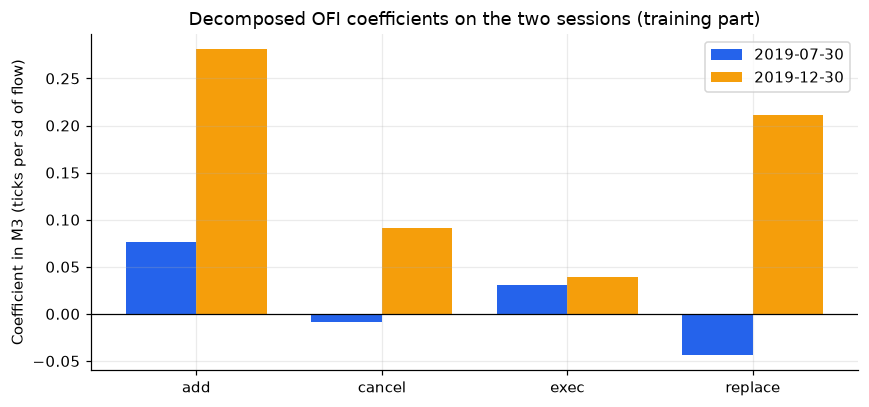

In [4]:
coef = pd.DataFrame({day: fits_by_day[day]["M3"].params[FLOW] for day in days}).T
t_values = pd.DataFrame({day: fits_by_day[day]["M3"].tvalues[FLOW] for day in days}).T
coef.columns = t_values.columns = GROUPS
print("coefficients:")
print(coef.round(3).to_string())
print("t-statistics:")
print(t_values.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
width = 0.38
position = np.arange(len(GROUPS))
for shift, (day, color) in zip((-width / 2, width / 2), zip(days, ("#2563eb", "#f59e0b"))):
    ax.bar(position + shift, coef.loc[day], width, color=color, label=str(day))
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(position, GROUPS)
ax.set_ylabel("Coefficient in M3 (ticks per sd of flow)")
ax.set_title("Decomposed OFI coefficients on the two sessions (training part)")
ax.legend()
plt.tight_layout()
plt.show()

<a id="conclusion"></a>

## 5. Conclusion and limits

**H1 holds on the second day, but the size of the effect depends on the day.**
- Within each day, the OFI coefficient is positive and significant (t = 2.3 in July, 5.4 in
  December). Out of sample, M2 has a lower MSE than M1 on both days. The Clark-West test is
  strongly significant in December (p < 0.001) but only borderline in July (p = 0.09).
- When the model is fitted on one day and tested on the other, the Clark-West test is significant
  in both directions (t = 6.3 and 2.3).
- The effect is about five times smaller in July (0.056 against 0.29 ticks per standard deviation
  of OFI). In July the spread is tighter and the price moves half as much, so the same imbalance
  moves the mid-price less.
- This is also why the December model does worse than M1 on July in raw MSE (5.787 against 5.740),
  although the Clark-West test is significant. Clark-West corrects for the noise of the extra
  coefficient and asks whether the OFI carries information. It does not ask whether a coefficient
  estimated on another day has the right size.
- In practice the slope has to be re-estimated on recent data, or scaled by the volatility of the
  day.

**H2 is not supported.** The two days give opposite answers:

| | 2019-07-30 | 2019-12-30 |
|---|---|---|
| Wald, equal coefficients (in sample) | not rejected (p = 0.17) | rejected (p < 0.001) |
| Clark-West M2 to M3 (out of sample) | significant (p = 0.01) | not significant (p = 0.67) |

Across days, M3 does not beat M2 in either direction (p = 0.44 and 0.47). The coefficients of
section 4 are not stable either. The add flow has the largest positive coefficient on both days,
but cancellations and replacements change sign between the two sessions. The only part of the
decomposition that looks robust is the weight of the add flow. Splitting the flow into four groups
adds three parameters, and their estimates do not carry over from one session to the next. This
is consistent with notebook 03: the total OFI summarizes the useful information about as well as
its decomposition does.

**Limits.**
- Two days are still a small sample. They show that the December results are not a pure
  accident, but they cannot tell how often each pattern occurs. More sessions, ideally
  consecutive ones, would allow a proper combination of the daily tests.
- The days were not drawn at random. Nasdaq only publishes a few sample files, and July 30 is a
  pre-earnings day (Apple reported after the close), which may lower activity.
- Only one stock, one horizon (5 s) and best-level OFI are studied.
- Within a day, the best model improves the MSE of the zero forecast by less than 0.5 %. Across
  days, the models fitted on December do worse than the zero forecast on July. The gains are
  statistical, not economic: no transaction costs or trading rule are considered.